# Monitoreo estadístico: calidad de cartera SFC

## Decisión
¿Un indicador agregado por entidad se aleja de su comportamiento histórico? Se construye un ejemplo de vigilancia mensual para cartera comercial de Banco de Bogotá, usando la serie pública transformada de la SFC. Una alerta señala revisión de datos y contexto; no identifica fallas de control, pérdidas ni causalidad.

## Fuente y diseño
Fuente: [calidad de cartera SFC](https://www.superfinanciera.gov.co/loader.php?idFile=1070109&lFuncion=descargar&lServicio=Tools2&lTipo=descargas), corte 2023, y [companion reproducible](../../../01-credit-risk/credit-risk-products/observed-sfc-quality-proxy/README.md). Se fija una ventana inicial 2011–2017 y se revisa 2018–2023 sin reajustar límites. Banda ilustrativa: media ± 3 desviaciones estándar; también se examina la autocorrelación de primer orden. [NIST](https://www.nist.gov/publications/statistical-process-monitoring-autocorrelated-data) advierte que la dependencia temporal afecta el uso de gráficos de control. Los límites no garantizan una tasa de falsa alarma cuando hay dependencia o cambios de régimen.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt, hashlib
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'03-financial-risk').is_dir())
plt.rcParams.update({'figure.figsize':(10,4),'axes.grid':True})

## Preparación y comprobaciones
La llave es fecha, modalidad, tipo y código de entidad. No se rellenan meses faltantes. El porcentaje es un indicador agregado de cartera vencida, no el desempeño de un control operativo.

In [2]:
p=root/'03-financial-risk/01-credit-risk/credit-risk-products/observed-sfc-quality-proxy/results/sfc_icv_entity_modality_month.csv'
df=pd.read_csv(p,parse_dates=['period']);print('SHA-256 extracto:',hashlib.sha256(p.read_bytes()).hexdigest())
print('Nombres que contienen Bogota:',sorted(df.loc[df.entity_name.str.contains('Bogota',case=False,na=False),'entity_name'].unique()))
d=df[(df.modality=='Comercial')&(df.entity_type_code==1)&(df.entity_code==1)].sort_values('period').copy()
assert not d.period.duplicated().any() and d.icv_reported_pct.notna().all()
expected=pd.date_range(d.period.min(),d.period.max(),freq='ME');missing=expected.difference(d.period)
print('Meses:',len(d),'| faltantes:',len(missing),'| periodo:',d.period.min().date(),'a',d.period.max().date())
assert len(missing)==0, 'Los meses faltantes requieren revisión previa'
d[['period','entity_name','icv_reported_pct']].tail()

SHA-256 extracto: 333144bae0eeae4713137a65a7126e7f39e2fe0bcf89337b366dda464e0c2fa8
Nombres que contienen Bogota: ['Bogota']
Meses: 156 | faltantes: 0 | periodo: 2011-01-31 a 2023-12-31


,period,entity_name,icv_reported_pct
151,2023-08-31,Bogota,3.610969
152,2023-09-30,Bogota,3.545632
153,2023-10-31,Bogota,3.811713
154,2023-11-30,Bogota,3.744060
155,2023-12-31,Bogota,3.604537


## Línea base y evaluación temporal
Los parámetros se estiman solo en la línea base. La tasa de alertas posterior se presenta como frecuencia descriptiva de los meses disponibles; no es una probabilidad futura.

In [3]:
baseline=d[d.period<'2018-01-01'].copy(); monitoring=d[d.period>='2018-01-01'].copy()
assert len(baseline)>12 and len(monitoring)>0
mu=baseline.icv_reported_pct.mean(); sd=baseline.icv_reported_pct.std(ddof=1); assert sd>0
lower=max(0,mu-3*sd); upper=mu+3*sd
monitoring['alerta']=(monitoring.icv_reported_pct<lower)|(monitoring.icv_reported_pct>upper)
print('Base:',len(baseline),'meses | media:',round(mu,3),'| desviación:',round(sd,3),'| límites:',round(lower,3),round(upper,3))
print('Posterior:',len(monitoring),'meses | alertas:',int(monitoring.alerta.sum()),'| frecuencia:',round(monitoring.alerta.mean(),4))
print('Autocorrelación de primer orden en base:',round(baseline.icv_reported_pct.autocorr(lag=1),3))
monitoring.loc[monitoring.alerta,['period','icv_reported_pct']].head(12)

Base: 84 meses | media: 1.843 | desviación: 0.578 | límites: 0.108 3.577
Posterior: 72 meses | alertas: 50 | frecuencia: 0.6944
Autocorrelación de primer orden en base: 0.967


,period,icv_reported_pct
90,2018-07-31,4.047893
91,2018-08-31,3.908777
92,2018-09-30,3.767622
93,2018-10-31,3.743640
94,2018-11-30,3.803235
95,2018-12-31,3.787118
96,2019-01-31,4.274438
97,2019-02-28,4.327647
98,2019-03-31,3.871598
99,2019-04-30,3.890717


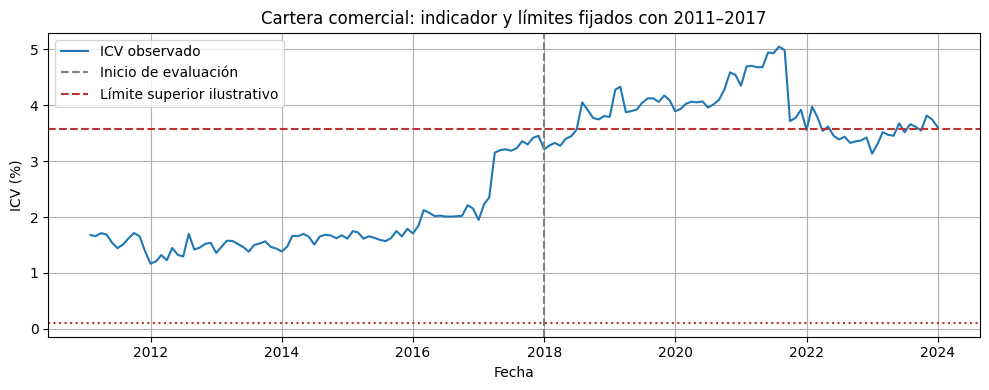

In [4]:
fig,ax=plt.subplots();ax.plot(d.period,d.icv_reported_pct,label='ICV observado');ax.axvline(pd.Timestamp('2018-01-01'),color='grey',ls='--',label='Inicio de evaluación');ax.axhline(upper,color='#b33',ls='--',label='Límite superior ilustrativo');ax.axhline(lower,color='#b33',ls=':');ax.set(title='Cartera comercial: indicador y límites fijados con 2011–2017',xlabel='Fecha',ylabel='ICV (%)');ax.legend();plt.tight_layout();plt.show()

## Sensibilidad y límites
Un umbral de 2σ permite comparar sensibilidad de alertas con el de 3σ, sin elegir uno por el resultado. El indicador es público y agregado; se necesitan registros de controles, incidentes, resultados y criterios acordados para validar un sistema de aseguramiento.

In [5]:
rows=[]
for k in [2,3,4]:
 lo=max(0,mu-k*sd);hi=mu+k*sd;flag=(monitoring.icv_reported_pct<lo)|(monitoring.icv_reported_pct>hi)
 rows.append({'desviaciones':k,'limite_inferior_pct':lo,'limite_superior_pct':hi,'meses':len(flag),'alertas':int(flag.sum()),'frecuencia_observada':flag.mean()})
pd.DataFrame(rows).round(4)

,desviaciones,limite_inferior_pct,limite_superior_pct,meses,alertas,frecuencia_observada
0,2,0.6865,2.9992,72,72,1.0000
1,3,0.1084,3.5774,72,50,0.6944
2,4,0.0000,4.1555,72,15,0.2083


## Uso responsable
El cambio de una serie financiera puede deberse a economía, metodología, composición o datos. Antes de escalar una alerta, revisar publicación, definiciones, integridad y contexto; no extrapolar la frecuencia observada a otra institución o periodo.

En el corte ejecutado, la autocorrelación de la base es 0,967 y 50 de 72 meses posteriores superan los límites. La dependencia y posibles cambios de régimen impiden interpretar esa frecuencia como tasa de fallos de controles o como falsa alarma calibrada; se requiere revisar una línea base y método específicos antes de usar el indicador operativamente.